# Age Estimation and Gender Classification

In this assignment, you will train CNN models to estimate a person's age and predict their gender based on face images. Please read carefully all the instructions before you start to write your code.

**Your Tasks**

You are supposed to train two CNN models.
- Model A: Train a CNN model from scratch, following a few restrictions. Save this model as `age_gender_A.keras`
- Model B: Fine-tune a pre-trained model to perform the same task. Save this model as `age_gender_B.keras`

**Dataset**

Your models will be trained and validated on a folder `train_val/` containing 5,000 labeled face images (size: 128 x 128), originated from the UTKFace dataset. During the assessment phase, your code will be tested on unseen test data.

**Performance Metric**

The evaluation of your models on the test set will be based on the following metrics:
- age estimation: - Mean Absolute Error (MAE)
- gender prediction: accuracy

**GPU Time Management**

Please use the available GPU time wisely, as there are some limitations on free GPU usage. It is said the users can use up to 12 hours in row in Google Colab. But many people found they reached its limit far less than 12 hours. To minimize the risk of reaching the limit, consider the following suggestions:
1. Ensure you have a stable internet connection.
2. Carefully validate your hyperparameters before starting the training process.
3. Based on past experience, each model should be trained in less than 2 hours. If the training time is significantly longer, you may need to adjust your model architecture.


## Setting Up: Mount the google drive
Mount your google drive to the notebook. Also don't forget to **enable GPU** before your training.


In [ ]:
#
# Add your code here
#
#Part A : Mounted google drive
from google.colab import drive
drive.mount('/content/drive')

#Part B : Check GPU availability
# Check GPU availability
import tensorflow as tf
print("GPU Available: ", tf.config.list_physical_devices('GPU'))
print("TensorFlow version: ", tf.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version:  2.19.0


## Visualize a few photos
It's always beneficial to thoroughly understand your data before beginning the training process. To get a first-hand impression of the dataset, please display a minimum of 20 images from the `train_val/` folder, along with their corresponding age and gender labels. This will help you gain initial insights into the dataset.

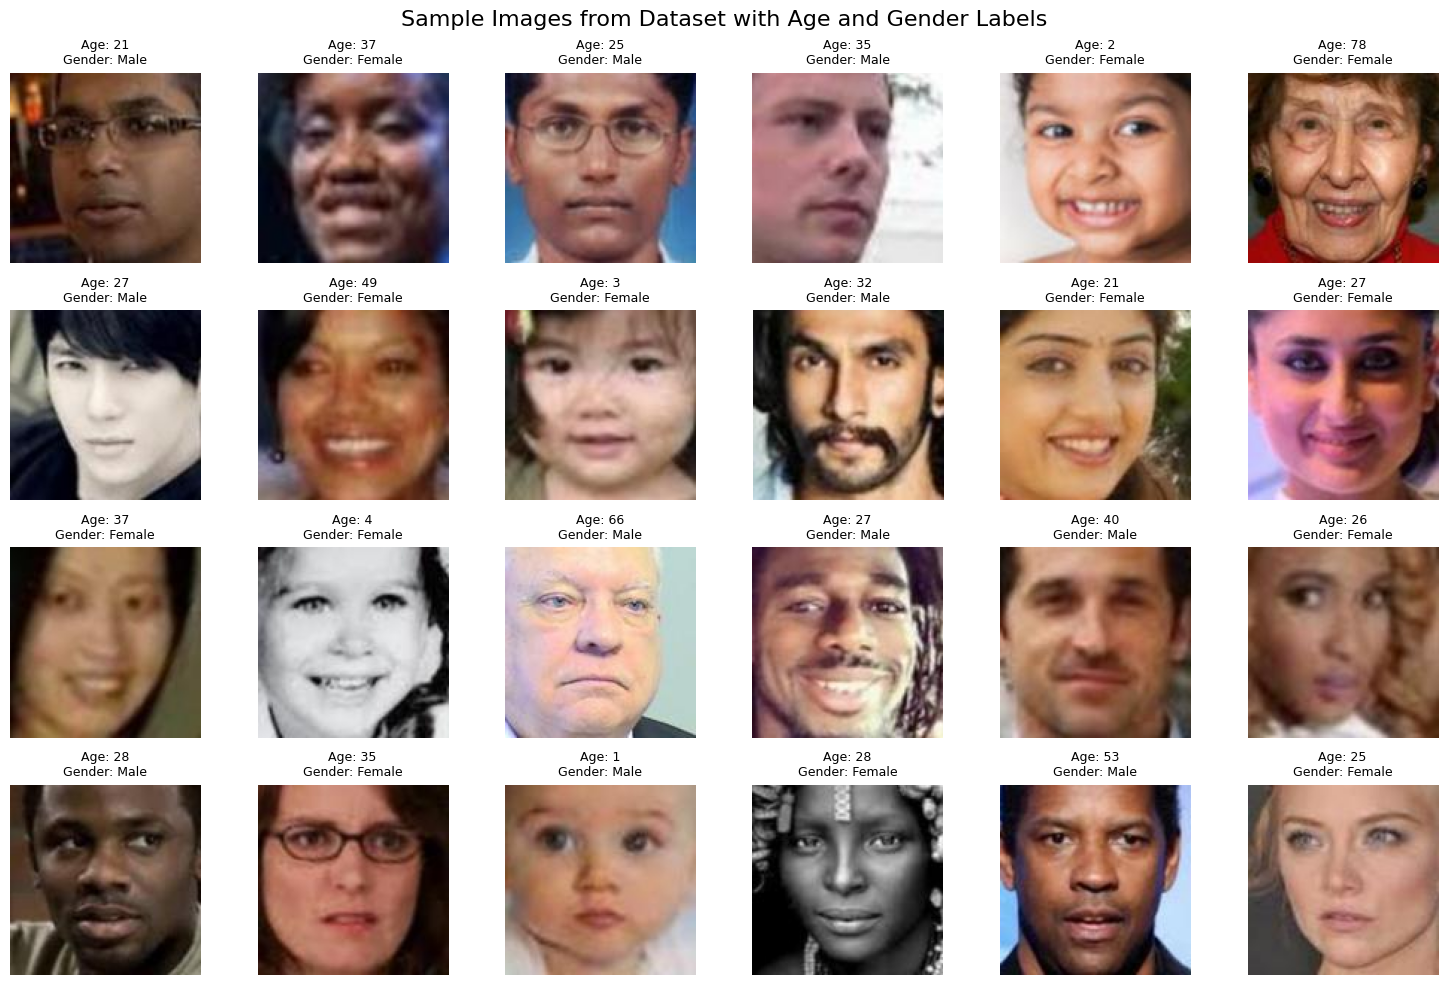

Displayed 24 images from the dataset


In [ ]:
#
# Add your code here
#

import cv2
import matplotlib.pyplot as plt
import os

# Set the path to train_val folder (adjust this path based on your Google Drive structure)
folder_train_val = '/content/drive/MyDrive/train_val'  # Update this path as needed

# Get all image files
all_image_files = [file for file in os.listdir(folder_train_val) if file.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Display at least 20 images
num_images_to_show = min(24, len(all_image_files))  # Show 24 images in a 4x6 grid
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle('Sample Images from Dataset with Age and Gender Labels', fontsize=16)

for idx in range(num_images_to_show):
    img_path = os.path.join(folder_train_val, all_image_files[idx])
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Parse labels from filename (format: age_gender_race_date.jpg)
    labels = all_image_files[idx].split('_')
    age_label = int(labels[0])
    gender_label = int(labels[1])  # 0 for male, 1 for female

    row = idx // 6
    col = idx % 6
    axes[row, col].imshow(img_rgb)
    axes[row, col].set_title(f'Age: {age_label}\nGender: {"Female" if gender_label == 1 else "Male"}',
                            fontsize=9)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

print(f"Displayed {num_images_to_show} images from the dataset")

## Step 1: Data Pre-Processing
In this step, you will perform necessary pre-processing tasks before feeding the data into a CNN. The pre-processing includes:

1. Splitting the data into training and validation sets.
2. Loading image data, gender labels and age values, and rescaling pixel values (originally integers between 0 and 255) to the range [0, 1].
3. Data augmentation

The first two pre-processing steps have already been completed for you. Your task in this step is limited to:

3. Data augmentation

Please note:

- Do not modify any part of the provided code except the section marked with ########.
- Do not rescale the age values to the range [0,1], as the original values are used during the testing stage. Rescaling them would significantly impact testing performance.



In [ ]:
import os
import random
import numpy as np

folder_train_val = "/content/drive/MyDrive/train_val"
all_image_files = [file for file in os.listdir(folder_train_val) if file.lower().endswith(('.jpg'))]

# Shuffle the dataset to ensure random distribution
random.seed(0)  # Ensure reproducibility
random.shuffle(all_image_files)

# Calculate the number of images for each set
n_train_val = len(all_image_files)
train_end = int(n_train_val * 0.8)

# Split the dataset
train_image_files = all_image_files[:train_end]
val_image_files = all_image_files[train_end:]
print(f"Number of images for training: {len(train_image_files)}")
print(f"Number of images for validation: {len(val_image_files)}")

def load_imgs_lables(dataset_path,filenames):
  print('load all image data, age and gender labels...')
  images = []
  age_labels = []
  gender_labels = []
  for current_file_name in filenames:
    img = cv2.imread(os.path.join(dataset_path, current_file_name))
    img = img / 255.0  # Normalize pixel values
    labels = current_file_name.split('_')
    age_label = int(labels[0])
    gender_label = int(labels[1])
    age_labels.append(age_label)
    gender_labels.append(gender_label)
    images.append(img)

  # Convert to NumPy arrays
  images = np.array(images)
  age_labels = np.array(age_labels)
  gender_labels = np.array(gender_labels)
  return images, age_labels, gender_labels

# load data from the training set
train_images, train_age, train_gender = load_imgs_lables(folder_train_val,train_image_files)

# load data from the validation set
val_images, val_age, val_gender = load_imgs_lables(folder_train_val,val_image_files)

#
######### Add your code for data augmentation here #########
#
#This code uses the second method of augmentation that we learned in class. In this method, augmentation operates in the tf.data pipeline rather than inside the model.
#Only training images undergo a small data_augmentation block (horizontal flip + small rotation) during the .map(...) step. Validation images stay the same.
#The model's structure doesn't change; only the input pipeline is changed to add weak augmentation on the fly during training.
import tensorflow as tf

# Minimal on-the-fly augmentation pipeline (applied only to training data)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.03),
], name="data_augmentation")

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Build tf.data pipelines so the model architecture remains unchanged
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_images, {'gender_output': train_gender, 'age_output': train_age})
)
train_dataset = (
    train_dataset
    .shuffle(len(train_images), seed=0)
    .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_images, {'gender_output': val_gender, 'age_output': val_age})
)
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Data augmentation enabled: horizontal flip + small rotation applied during training")

Number of images for training: 4000
Number of images for validation: 1000
load all image data, age and gender labels...
load all image data, age and gender labels...
Data augmentation enabled: horizontal flip + small rotation applied during training


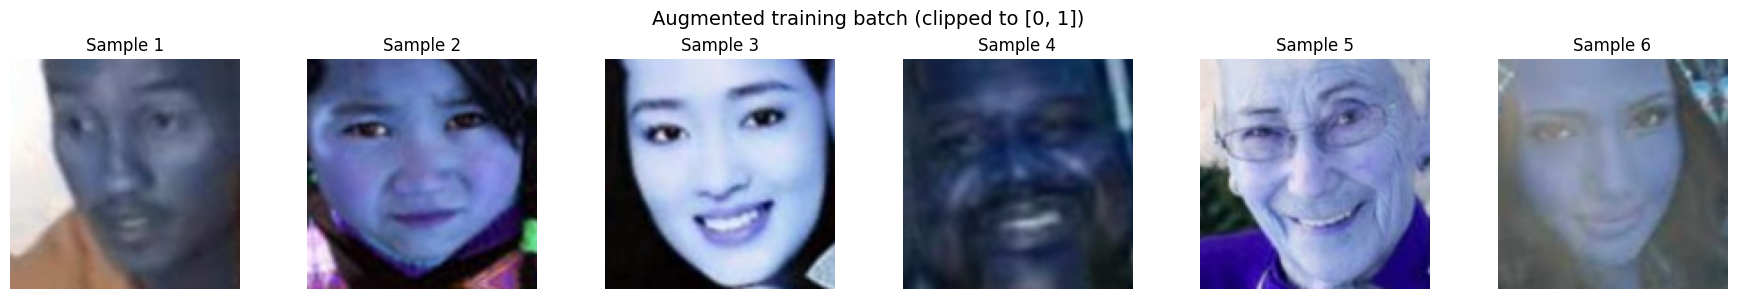

In [ ]:
# Quick visual check to ensure augmentation is not distorting faces
import matplotlib.pyplot as plt

aug_batch = next(iter(train_dataset.take(1)))
aug_images = aug_batch[0][:6].numpy()

fig, axes = plt.subplots(1, len(aug_images), figsize=(18, 3))
for idx, ax in enumerate(axes):
    ax.imshow(aug_images[idx])
    ax.axis('off')
    ax.set_title(f'Sample {idx+1}')

plt.suptitle('Augmented training batch (clipped to [0, 1])', fontsize=14)
plt.tight_layout()
plt.show()

# Data augmentation was effective for the UTKFace dataset only when it was kept weak and real. Light changes like small rotations and horizontal flips improved
# generalization without compromising facial details when there were 4,000 training images and 1,000 validation images. When strong rotations and big zooms were used,
#  the faces looked deformed, the skin texture and wrinkles appeared worse, and the training curves got noisier, which showed that heavy augmentation weakened the
#  useful age-related information.

## STEP2A: Build your own CNN network
In this step, you will define your own CNN model for identifying gender and predicting age. Although there are two tasks, you only need to build one CNN model with two outputs. You may refer to online resources for solutions.

Here are the key requirements and restrictions for your network:
1.	The input size must be 128 x 128 x 3, which means you **should not resize** the original images. This is because my test code relies on this particular input size. Any other size will cause problem in the testing stage.
2.  Please treat the gender classification as a binary problem, i.e., **the output layer for the gender branch has only 1 unit**, instead of 2. Although it is technically correct to treat gender classification as a multi-class problem with 2 classes, i.e., 2 units in the last layer, the test code only supports a 1-unit last-layer configuration for the gender branch.
3.	The size of feature maps being fed to the first fully connected layer must be less than 10 x 10, while there is no number limitation about the depth.
4.	Incorporate techniques to prevent overfitting as appropriate.

At the end of your implementation, use `modelA.summary()` to display the model architecture and use `plot_model()` to visualize the architecture.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 256) │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 16384)     │          0 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  4,194,560 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │  4,194,560 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │        257 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        257 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,778,050 (33.49 MB)

 Trainable params: 8,778,050 (33.49 MB)

 Non-trainable params: 0 (0.00 B)

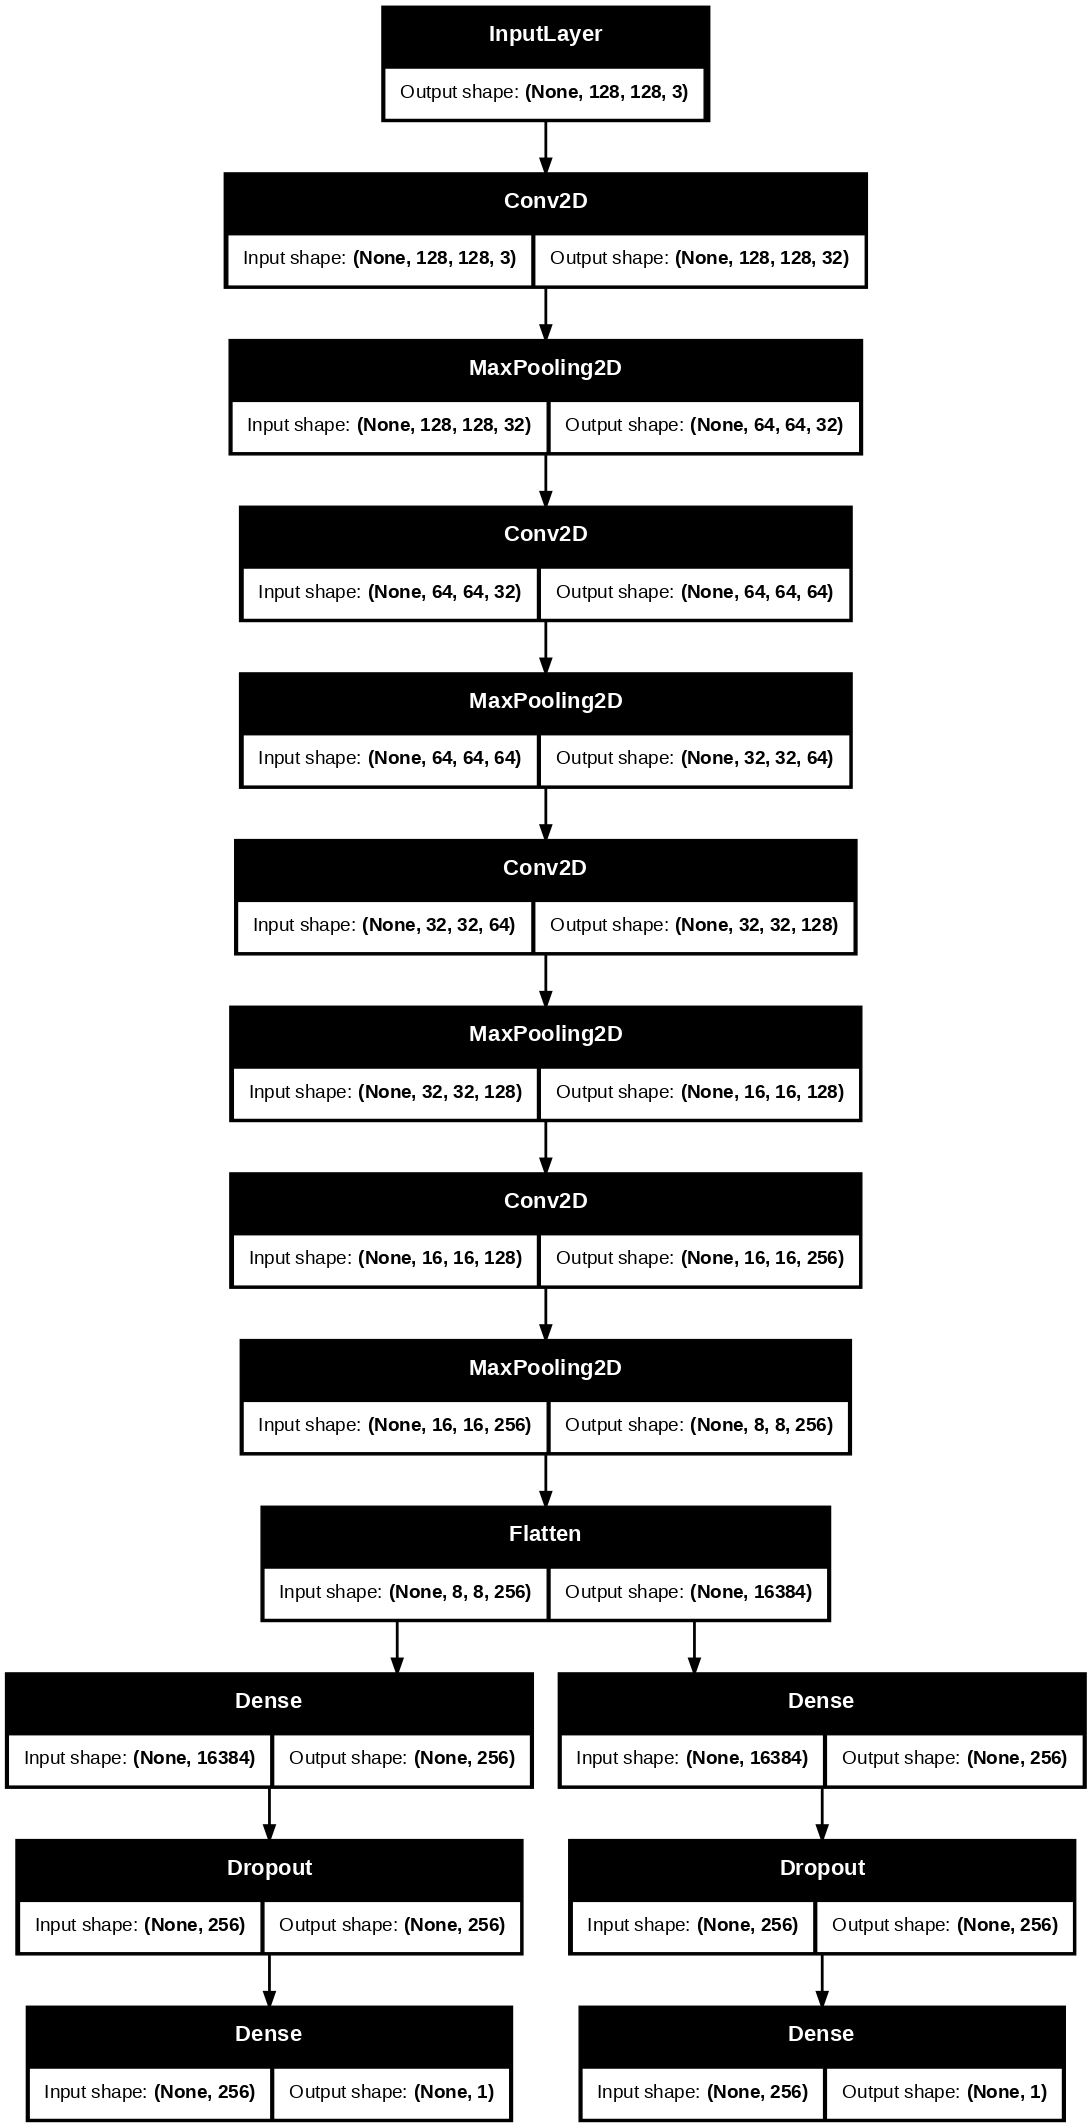

In [ ]:
#
# Add your code here
#

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#I used multiple 3×3 convolution layers with ReLU and max pooling instead of a single large 7×7 layer because this is more parameter‑efficient and helps reduce
#overfitting while still giving a similar receptive field. Stacking several 3×3 layers also introduces more non‑linearities, allowing the network to learn more
#complex features. ReLU activations make training more stable and mitigate vanishing gradients. Max pooling progressively reduces spatial dimensions and focuses on
# the most salient facial features, which improves generalisation.

# Build Model A: CNN from scratch with dual outputs
def build_model_A():
    inputs = keras.Input(shape=(128, 128, 3))

    # Convolutional block
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Flatten()(x)

    dense_1 = layers.Dense(256, activation='relu')(x)
    dense_2 = layers.Dense(256, activation='relu')(x)
    dropout_1 = layers.Dropout(0.3)(dense_1)
    dropout_2 = layers.Dropout(0.3)(dense_2)

    # Gender branch (binary classification with 1 unit)
    gender_output = layers.Dense(1, activation='sigmoid', name='gender_output')(dropout_1)

    # Age branch (regression)
    age_output = layers.Dense(1, activation='relu', name='age_output')(dropout_2)

    # Create model with dual outputs
    model = keras.Model(inputs=inputs, outputs=[gender_output, age_output])

    return model

modelA = build_model_A()

modelA.summary()
from tensorflow.keras.utils import plot_model
plot_model(modelA, show_shapes=True,dpi=100)

## STEP3A: Compile and train your model
Compile and train your model here.
Save your model by `modelA.save(your_model_folder+"age_gender_A.keras")` after training.

**DON'T use any other name for your model file.** This is because my test code relies on this particular model name. Any other file name will cause problem in the testing stage.

**Save the model with `save()`** to save the entire model (including a model's architecture, weights, and training configuration) as a `.keras` zip archive. Don't save it with `save_weights()`.


In [ ]:
#
# Add your code here
#

 # Compile with separate losses for each output
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Define folder for saving models
folder_models = '/content/drive/MyDrive/models/'
# Create directory if it doesn't exist
import os
os.makedirs(folder_models, exist_ok=True)

# Model A is compiled with Adam (lr=0.001) and separate losses for each output:
# binary cross-entropy + accuracy for gender, and MAE for age. EarlyStopping and
# ReduceLROnPlateau are used to prevent overfitting and to automatically reduce
# the learning rate when the validation loss stops improving.

# Compile the model
modelA.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss={
        'gender_output': 'binary_crossentropy',
        'age_output': 'mae'
    },
    metrics={
        'gender_output': 'accuracy',
        'age_output': 'mae'
    }
)

# Define callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

# train model
historyA = modelA.fit(
    train_dataset,
    epochs=50,
    batch_size=32,
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=1
)
modelA.save(folder_models+'age_gender_A.keras')
print(f"Model A saved to {folder_models}age_gender_A.keras")

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 134ms/step - age_output_loss: 18.4806 - age_output_mae: 18.4806 - gender_output_accuracy: 0.5243 - gender_output_loss: 0.7968 - loss: 19.2774 - val_age_output_loss: 17.2693 - val_age_output_mae: 17.1783 - val_gender_output_accuracy: 0.6180 - val_gender_output_loss: 0.6825 - val_loss: 17.8609 - learning_rate: 0.0010
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - age_output_loss: 15.3475 - age_output_mae: 15.3475 - gender_output_accuracy: 0.5591 - gender_output_loss: 0.6809 - loss: 16.0284 - val_age_output_loss: 14.9606 - val_age_output_mae: 14.8996 - val_gender_output_accuracy: 0.6490 - val_gender_output_loss: 0.6477 - val_loss: 15.5475 - learning_rate: 0.0010
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - age_output_loss: 14.7946 - age_output_mae: 14.7946 - gender_output_accuracy: 0.6416 - gender_output_loss: 0.6357 - loss: 15.4304 - val_age_output_loss: 14.0612 - val_age_output_mae: 13.9685 - val_gender_output_accuracy: 0.6

## STEP4A: Draw the learning curves
Draw four learning curve figures for model A as follows.
1.	The loss of the gender classification over the training and validation set
2.	The accuracy of the gender classification over the training and validation set
3.	The loss of the age estimation over the training and validation set
4.	The MAE of the age estimation over the training and validation set

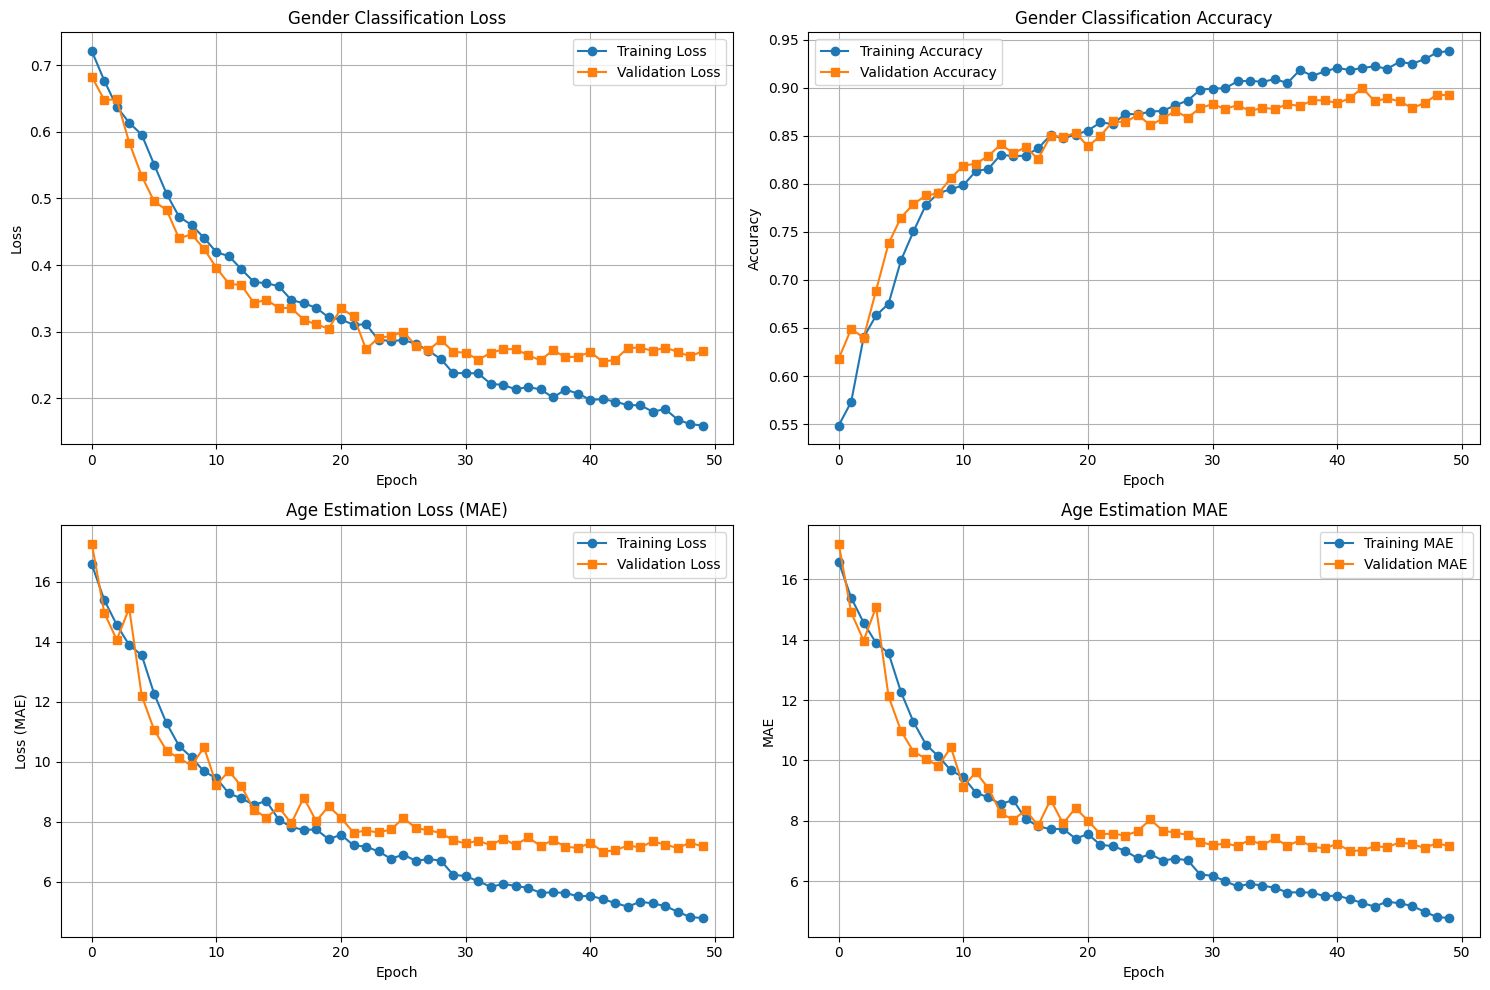

In [ ]:
#
# Add your code here
#
# Plot the training history of Model A: training vs validation loss/accuracy
# for gender, and training vs validation loss/MAE for age. These curves help
# diagnose underfitting or overfitting and identify the epoch with the best
# validation performance.

import matplotlib.pyplot as plt

# Plot 1: Gender classification loss
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(historyA.history['gender_output_loss'], label='Training Loss', marker='o')
plt.plot(historyA.history['val_gender_output_loss'], label='Validation Loss', marker='s')
plt.title('Gender Classification Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Gender classification accuracy
plt.subplot(2, 2, 2)
plt.plot(historyA.history['gender_output_accuracy'], label='Training Accuracy', marker='o')
plt.plot(historyA.history['val_gender_output_accuracy'], label='Validation Accuracy', marker='s')
plt.title('Gender Classification Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot 3: Age estimation loss
plt.subplot(2, 2, 3)
plt.plot(historyA.history['age_output_loss'], label='Training Loss', marker='o')
plt.plot(historyA.history['val_age_output_loss'], label='Validation Loss', marker='s')
plt.title('Age Estimation Loss (MAE)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.grid(True)

# Plot 4: Age estimation MAE
plt.subplot(2, 2, 4)
plt.plot(historyA.history['age_output_mae'], label='Training MAE', marker='o')
plt.plot(historyA.history['val_age_output_mae'], label='Validation MAE', marker='s')
plt.title('Age Estimation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#Model A trains stably for both tasks. Gender accuracy rises from ~0.52 to ~0.95 on the training set and to ~0.89 on validation, with losses decreasing smoothly, showing good fit and only mild overfitting.
#Age MAE drops from ~18.5 to ~4.8 (train) and ~17.2 to ~7.1 (val) and then plateaus, indicating the model has learned useful age features and that early stopping + ReduceLROnPlateau keep validation performance stable.

## STEP2B: Build a CNN network based on a pre-trained model
Choose an existing CNN architecture pre-trained on ImageNet and fine-tune it on this dataset.

As with Model A, **do not resize the input image size**.
Ensure that the output layer for **the gender branch has only 1 unit**.

At the end of the cell, use `modelB.summary()` to display the model architecture and use `plot_model()` to visualize the architecture.


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_1… │ (None, 4, 4,      │  2,257,984 │ input_layer_12[0… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 1280)      │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 256)       │    327,936 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 256)       │          0 │ dense_5[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │     16,448 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │         65 │ dense_6[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        257 │ dropout_11[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,602,690 (9.93 MB)

 Trainable params: 344,706 (1.31 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_14      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_1… │ (None, 4, 4,      │  2,257,984 │ input_layer_14[0… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 1280)      │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 256)       │    327,936 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 256)       │          0 │ dense_7[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │     16,448 │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │         65 │ dense_8[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        257 │ dropout_13[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,602,690 (9.93 MB)

 Trainable params: 344,706 (1.31 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

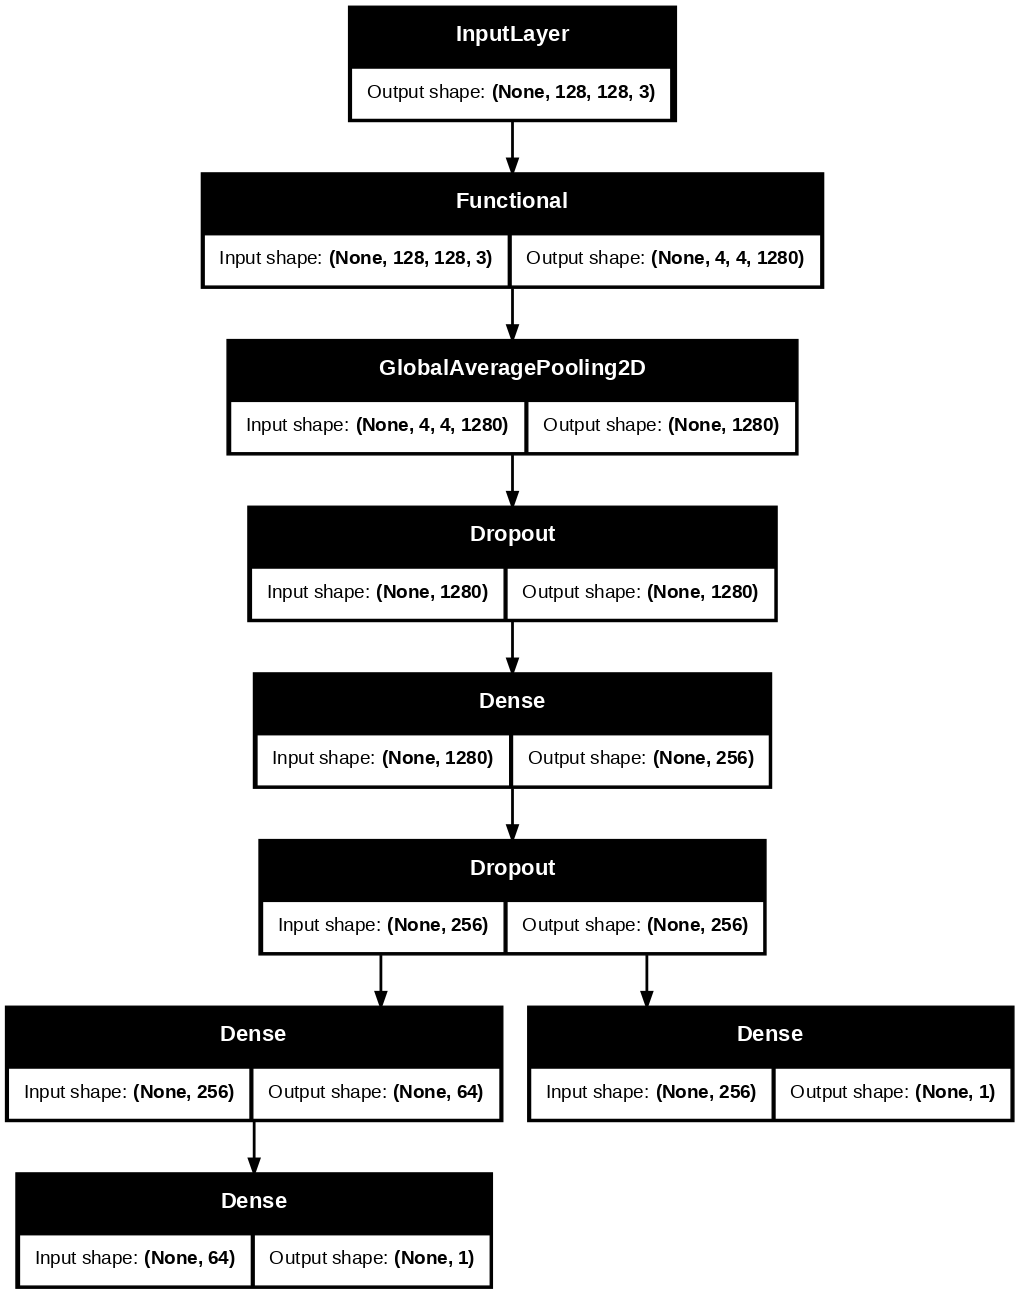

In [ ]:
# Model B: Transfer learning with MobileNetV2 backbone
# - Use an ImageNet-pretrained MobileNetV2 (no top) as a frozen feature extractor
# - Add a small task-specific head and two outputs (gender: sigmoid, age: ReLU)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_model_B():
    from tensorflow.keras.applications import MobileNetV2
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(128, 128, 3)
    )
    base_model.trainable = False

    inputs = keras.Input(shape=(128, 128, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    # Shared head
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)

    # Small gender-specific branch
    #Compared to Model A, Model B includes a small gender‑specific Dense layer after the shared head. This extra layer allows the network to learn features that are
    #tailored to the gender task (for example, hairline or facial‑hair cues) without forcing the age branch to use the same representation, which empirically helped
    #gender accuracy while keeping age MAE stable.
    g = layers.Dense(64, activation='relu')(x)
    gender_output = layers.Dense(1, activation='sigmoid', name='gender_output')(g)

    # Age uses the shared representation directly
    age_output = layers.Dense(1, activation='relu', name='age_output')(x)

    model = keras.Model(inputs=inputs, outputs=[gender_output, age_output])
    model.base_model = base_model
    return model

modelB = build_model_B()
modelB.summary()


from tensorflow.keras.utils import plot_model
plot_model(modelB, show_shapes=True, dpi=100)


## STEP3B: Compile and train your model
Compile and train your model here.
Save your model to `age_gender_B.keras` after training.

**DON'T use any other name for your model file.** This is because my test code relies on this particular model name. Any other file name will cause problem in the testing stage.

**Also, save the model with `save()` instead of `save_weights()`.**


In [ ]:
# Model B is trained in two stages: first we train only the new head on top of
# a frozen ImageNet-pretrained backbone, then we unfreeze the last ~30 layers
# and fine-tune them with a lower learning rate, early stopping, and LR reduction.
# This warm-up + fine-tuning schedule helps adapt pretrained features to UTKFace
# while controlling overfitting on our relatively small dataset.

# Model B training: 2 stages (head warm-up, then partial fine-tuning)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import os

your_model_folder = '/content/drive/MyDrive/models/'
os.makedirs(your_model_folder, exist_ok=True)

WARMUP_EPOCHS = 10
TOTAL_EPOCHS = 50

# Emphasise gender a bit more (since age is already okay)
LOSS_WEIGHTS = {
    'gender_output': 0.6,
    'age_output': 0.4
}

# -----------------------
# Stage 1: head warm-up
# -----------------------
modelB.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss={
        'gender_output': 'binary_crossentropy',
        'age_output': 'mae'
    },
    loss_weights=LOSS_WEIGHTS,
    metrics={
        'gender_output': 'accuracy',
        'age_output': 'mae'
    }
)

callbacks_warmup = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

print("=" * 60)
print("Stage 1: Train only the classifier/regression head (backbone frozen)")
print("=" * 60)

historyB_stage1 = modelB.fit(
    train_dataset,
    epochs=WARMUP_EPOCHS,
    validation_data=val_dataset,
    callbacks=callbacks_warmup,
    verbose=1
)

# -----------------------
# Stage 2: fine-tuning
# -----------------------
base_model = modelB.base_model
fine_tune_at = max(0, len(base_model.layers) - 30)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

print(f"Unfroze {len(base_model.layers) - fine_tune_at} layers "
      f"(starting from layer index {fine_tune_at}) for fine-tuning")

modelB.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss={
        'gender_output': 'binary_crossentropy',
        'age_output': 'mae'
    },
    loss_weights=LOSS_WEIGHTS,
    metrics={
        'gender_output': 'accuracy',
        'age_output': 'mae'
    }
)

callbacks_finetune = [
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-7,
        verbose=1
    )
]

print("=" * 60)
print("Stage 2: Fine-tune the unfrozen backbone layers")
print("=" * 60)

historyB_stage2 = modelB.fit(
    train_dataset,
    epochs=TOTAL_EPOCHS,
    initial_epoch=WARMUP_EPOCHS,
    validation_data=val_dataset,
    callbacks=callbacks_finetune,
    verbose=1
)

# Merge histories
historyB = {}
for key in [
    'gender_output_loss', 'val_gender_output_loss',
    'gender_output_accuracy', 'val_gender_output_accuracy',
    'age_output_loss', 'val_age_output_loss',
    'age_output_mae', 'val_age_output_mae'
]:
    historyB[key] = historyB_stage1.history.get(key, []) + \
                    historyB_stage2.history.get(key, [])

modelB.save(your_model_folder + "age_gender_B.keras")
print(f"Model B saved to {your_model_folder}age_gender_B.keras")


Stage 1: Train only the classifier/regression head (backbone frozen)
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 31s 159ms/step - age_output_loss: 15.6546 - age_output_mae: 15.6546 - gender_output_accuracy: 0.5735 - gender_output_loss: 0.8659 - loss: 6.7814 - val_age_output_loss: 11.7478 - val_age_output_mae: 11.6670 - val_gender_output_accuracy: 0.7720 - val_gender_output_loss: 0.5269 - val_loss: 4.9801 - learning_rate: 0.0010
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 92ms/step - age_output_loss: 11.8289 - age_output_mae: 11.8289 - gender_output_accuracy: 0.6829 - gender_output_loss: 0.6442 - loss: 5.1181 - val_age_output_loss: 10.1191 - val_age_output_mae: 10.0887 - val_gender_output_accuracy: 0.7450 - val_gender_output_loss: 0.5158 - val_loss: 4.3451 - learning_rate: 0.0010
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 91ms/step - age_output_loss: 11.5115 - age_output_mae: 11.5115 - gender_output_accuracy: 0.7019 - gender_output_loss: 0.5880 - loss: 4.9574 - val_age_output_loss: 11.4490

## STEP4B: Draw the learning curves
Draw four learning curve figures for model B as follows.
1. The loss of the gender classification over the training and validation set
2. The accuracy of the gender classification over the training and validation set
3. The loss of the age estimation over the training and validation set
4. The MAE of the age estimation over the training and validation set

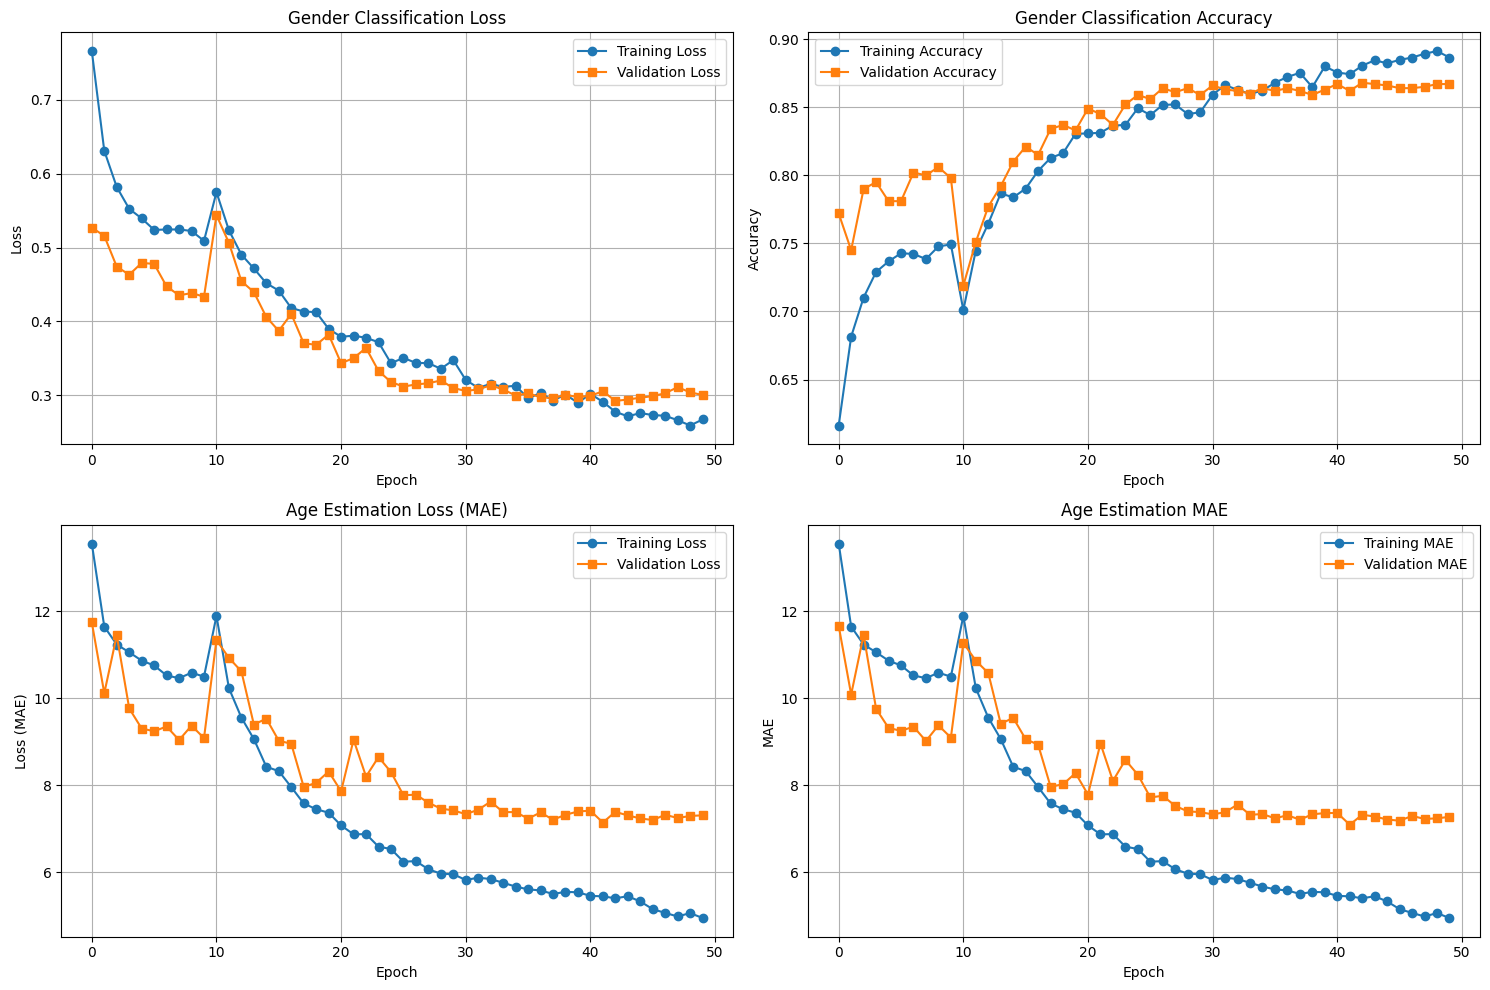

In [ ]:
#
# Add your code here
#
import matplotlib.pyplot as plt

def history_values(history_obj, key):
    if hasattr(history_obj, 'history'):
        return history_obj.history.get(key, [])
    return history_obj.get(key, [])

train_loss_gender = history_values(historyB, 'gender_output_loss')
val_loss_gender = history_values(historyB, 'val_gender_output_loss')
train_acc_gender = history_values(historyB, 'gender_output_accuracy')
val_acc_gender = history_values(historyB, 'val_gender_output_accuracy')
train_loss_age = history_values(historyB, 'age_output_loss')
val_loss_age = history_values(historyB, 'val_age_output_loss')
train_mae_age = history_values(historyB, 'age_output_mae')
val_mae_age = history_values(historyB, 'val_age_output_mae')

# Plot 1: Gender classification loss
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(train_loss_gender, label='Training Loss', marker='o')
plt.plot(val_loss_gender, label='Validation Loss', marker='s')
plt.title('Gender Classification Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Gender classification accuracy
plt.subplot(2, 2, 2)
plt.plot(train_acc_gender, label='Training Accuracy', marker='o')
plt.plot(val_acc_gender, label='Validation Accuracy', marker='s')
plt.title('Gender Classification Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot 3: Age estimation loss
plt.subplot(2, 2, 3)
plt.plot(train_loss_age, label='Training Loss', marker='o')
plt.plot(val_loss_age, label='Validation Loss', marker='s')
plt.title('Age Estimation Loss (MAE)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.grid(True)

# Plot 4: Age estimation MAE
plt.subplot(2, 2, 4)
plt.plot(train_mae_age, label='Training MAE', marker='o')
plt.plot(val_mae_age, label='Validation MAE', marker='s')
plt.title('Age Estimation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## STEP5: Evaluate the model on the test set
I will load your two models for testing. The test set will not be available before your submission.

The metrics for measuring the performance on the test set are:
- age estimation: MAE (Mean Absolute Error)
- gender classification: accuracy


In [ ]:
#
# Don't add code in this cell when submitting this file
#